<a href="https://colab.research.google.com/github/sponfork/HnC-Classifier/blob/main/Heart_Lung_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import os
import torch
import torchaudio
import pandas as pd

def clip_audio(audio_path, target_sr=16000, duration=3.0):
    target_samples = int(target_sr * duration)
    waveform, sr = torchaudio.load(audio_path)
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)
    if sr != target_sr:
        waveform = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)(waveform)

    # Pad or truncate to fixed duration
    if waveform.shape[1] < target_samples:
        waveform = torch.nn.functional.pad(waveform, (0, target_samples - waveform.shape[1]))
    else:
        waveform = waveform[:, :target_samples]
    return waveform

# Define output directory for HLS-CMDS clips
hls_output_dir = "/content/processed_hlscmds"
os.makedirs(hls_output_dir, exist_ok=True)

hls_metadata = []
hls_df = pd.read_csv("/content/drive/MyDrive/HLC_dataset/HLS-CMDS/HS.csv")

for _, row in hls_df.iterrows():
    sound_id = row['Heart Sound ID']
    path = os.path.join("/content/drive/MyDrive/HLC_dataset/HLS-CMDS/HS/HS", f"{sound_id}.wav")

    if os.path.exists(path):
        clipped_waveform = clip_audio(path)

        # Save each clip as a .pt file
        out_path = os.path.join(hls_output_dir, f"{sound_id}.pt")
        torch.save(clipped_waveform, out_path)

        hls_metadata.append({
            "path": out_path,
            "label": row['Heart Sound Type']
        })

# Save metadata dataframe for later training
hls_meta_df = pd.DataFrame(hls_metadata)
hls_meta_df.to_csv("/content/processed_hlscmds_meta.csv", index=False)

print(f"HLS-CMDS processed and saved: {len(hls_metadata)} clips")

HLS-CMDS processed and saved: 50 clips


In [18]:
import os
import pandas as pd
import torch
import torchaudio

def clip_physionet_audio(audio_path, target_sr=16000, duration=3.0):
    """
    Loads a PhysioNet audio recording, resamples to 16kHz, converts to mono,
    and pads/truncates to a fixed 3-second duration.
    """
    target_samples = int(target_sr * duration)

    # 1. Load the audio file
    waveform, sr = torchaudio.load(audio_path)

    # 2. Convert stereo to mono if needed
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)

    # 3. Resample to target sample rate (16kHz)
    if sr != target_sr:
        resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)
        waveform = resampler(waveform)

    # 4. Fixed-time padding or truncation
    num_samples = waveform.shape[1]
    if num_samples < target_samples:
        padding = target_samples - num_samples
        waveform = torch.nn.functional.pad(waveform, (0, padding))
    elif num_samples > target_samples:
        waveform = waveform[:, :target_samples]

    return waveform

def process_physionet_folder(base_dir, output_dir):
    """
    Iterates through PhysioNet training folders (a-f), reads REFERENCE.csv,
    clips each audio file, and saves the resulting tensor.
    """
    os.makedirs(output_dir, exist_ok=True)
    processed_metadata = []

    # Loop through training subfolders (e.g., training-a, training-b, etc.)
    for folder_name in sorted(os.listdir(base_dir)):
        folder_path = os.path.join(base_dir, folder_name)

        if os.path.isdir(folder_path):
            csv_path = os.path.join(folder_path, "REFERENCE.csv")

            if os.path.exists(csv_path):
                # Read the reference mapping file
                df = pd.read_csv(csv_path, header=None, names=["Recording_ID", "Label"])

                for _, row in df.iterrows():
                    rec_id = str(row["Recording_ID"])
                    label_str = str(row["Label"])

                    # Map label string to integer (Normal: 0, Abnormal: 1)
                    label = 0 if label_str.strip().lower() == "normal" else 1

                    # Safely construct path using os.path.join
                    audio_path = os.path.join(folder_path, f"{rec_id}.wav")

                    if os.path.exists(audio_path):
                        # Clip audio to 3 seconds
                        clipped_waveform = clip_physionet_audio(audio_path)

                        # Save the clipped tensor locally or to Drive
                        out_file_name = f"{rec_id}_clipped.pt"
                        out_path = os.path.join(output_dir, out_file_name)
                        torch.save(clipped_waveform, out_path)

                        processed_metadata.append({
                            "path": out_path,
                            "label": label
                        })

    print(f"Successfully clipped and saved {len(processed_metadata)} PhysioNet files.")
    return pd.DataFrame(processed_metadata)

base_dataset_dir = "/content/drive/MyDrive/training"
destination_dir = "/content/processed_physionet"
physio_df = process_physionet_folder(base_dataset_dir, destination_dir)

Successfully clipped and saved 3240 PhysioNet files.


In [19]:
import os
import pandas as pd
import torch
import torchaudio

def process_icbhi_single_folder(dataset_dir, output_dir, target_sr=16000, duration=3.0):
    """
    Scans a single folder containing both .wav and .txt files, matches them
    by base name, slices breath cycles, pads/truncates to 3 seconds, and saves as tensors.
    """
    os.makedirs(output_dir, exist_ok=True)
    processed_metadata = []
    target_samples = int(target_sr * duration)

    counter = 0

    # Get all unique base names by looking for .wav files
    files = sorted(os.listdir(dataset_dir))
    wav_files = [f for f in files if f.endswith(".wav")]

    for wav_file in wav_files:
        base_name = os.path.splitext(wav_file)[0]
        audio_path = os.path.join(dataset_dir, wav_file)
        txt_path = os.path.join(dataset_dir, f"{base_name}.txt")

        # Check if the matching .txt annotation file exists in the same folder
        if os.path.exists(txt_path):
            # Load the 4-column annotation file
            # Columns: Start_Time, End_Time, Crackles, Wheezes
            ann_df = pd.read_csv(txt_path, sep='\t', header=None, names=["start", "end", "crackle", "wheeze"])

            try:
                waveform, sr = torchaudio.load(audio_path)
            except Exception as e:
                print(f"Error loading {wav_file}: {e}")
                continue

            # Convert stereo to mono if necessary
            if waveform.shape[0] > 1:
                waveform = torch.mean(waveform, dim=0, keepdim=True)

            # Resample to target sample rate (16kHz)
            if sr != target_sr:
                resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)
                waveform = resampler(waveform)
                current_sr = target_sr
            else:
                current_sr = sr

            # Iterate through each annotated breath cycle
            for idx, row in ann_df.iterrows():
                start_sample = int(row["start"] * current_sr)
                end_sample = int(row["end"] * current_sr)

                # Slice the specific breath cycle
                cycle_waveform = waveform[:, start_sample:end_sample]

                # Apply fixed-time padding or truncation (3 seconds)
                num_samples = cycle_waveform.shape[1]
                if num_samples < target_samples:
                    padding = target_samples - num_samples
                    cycle_waveform = torch.nn.functional.pad(cycle_waveform, (0, padding))
                elif num_samples > target_samples:
                    cycle_waveform = cycle_waveform[:, :target_samples]

                # Determine multiclass label based on Crackle and Wheeze flags
                # 0: Normal, 1: Crackle only, 2: Wheeze only, 3: Both
                crackle = int(row["crackle"])
                wheeze = int(row["wheeze"])

                if crackle == 0 and wheeze == 0:
                    label = 0
                elif crackle == 1 and wheeze == 0:
                    label = 1
                elif crackle == 0 and wheeze == 1:
                    label = 2
                else:
                    label = 3

                # Save the processed cycle tensor
                out_file_name = f"{base_name}_cycle_{idx}.pt"
                out_path = os.path.join(output_dir, out_file_name)
                torch.save(cycle_waveform, out_path)

                processed_metadata.append({
                    "path": out_path,
                    "label": label
                })
                counter += 1

    print(f"Successfully extracted, clipped, and saved {counter} ICBHI breath cycles.")
    return pd.DataFrame(processed_metadata)

icbhi_folder = "/content/drive/MyDrive/ICBHI_final_database.1/ICBHI_final_database"
icbhi_output = "/content/processed_icbhi"
icbhi_df = process_icbhi_single_folder(icbhi_folder, icbhi_output)

Successfully extracted, clipped, and saved 6898 ICBHI breath cycles.


In [20]:
import os
import torch
import torchaudio

def convert_waveforms_to_log_mel(input_dir, output_dir, sample_rate=16000, n_mels=128):
    """
    Loads saved 3-second waveform tensors, converts them to Log-Mel Spectrograms,
    and saves them as new .pt tensors ready for the AST model.
    """
    os.makedirs(output_dir, exist_ok=True)

    # Initialize the torchaudio Log-Mel transform
    # AST models typically expect 128 Mel bins
    mel_transform = torchaudio.transforms.MelSpectrogram(
        sample_rate=sample_rate,
        n_fft=1024,
        hop_length=160,
        n_mels=n_mels
    )

    # Amplitude to DB (Log scale)
    db_transform = torchaudio.transforms.AmplitudeToDB(stype='power', top_db=80)

    counter = 0
    for file_name in os.listdir(input_dir):
        if file_name.endswith(".pt"):
            file_path = os.path.join(input_dir, file_name)

            # Load the clipped waveform tensor (shape: [1, 48000] for 3s at 16kHz)
            waveform = torch.load(file_path)

            # Compute Mel Spectrogram -> Convert to Log-Mel (dB)
            mel_spec = mel_transform(waveform)
            log_mel_spec = db_transform(mel_spec)

            # Save the resulting 2D spectrogram tensor
            out_path = os.path.join(output_dir, file_name)
            torch.save(log_mel_spec, out_path)
            counter += 1

    print(f"Successfully converted and saved {counter} Log-Mel spectrogram tensors.")

# 1. Convert PhysioNet Waveforms to Log-Mel Spectrograms
convert_waveforms_to_log_mel(
    input_dir="/content/processed_physionet",
    output_dir="/content/spectrograms_physionet"
)

# 2. Convert HLS-CMDS Waveforms to Log-Mel Spectrograms
convert_waveforms_to_log_mel(
    input_dir="/content/processed_hlscmds",
    output_dir="/content/spectrograms_hlscmds"
)

# 3. Convert ICBHI Waveforms to Log-Mel Spectrograms (if you haven't yet)
convert_waveforms_to_log_mel(
    input_dir="/content/processed_icbhi",
    output_dir="/content/spectrograms_icbhi"
)

Successfully converted and saved 3240 Log-Mel spectrogram tensors.
Successfully converted and saved 50 Log-Mel spectrogram tensors.
Successfully converted and saved 6898 Log-Mel spectrogram tensors.


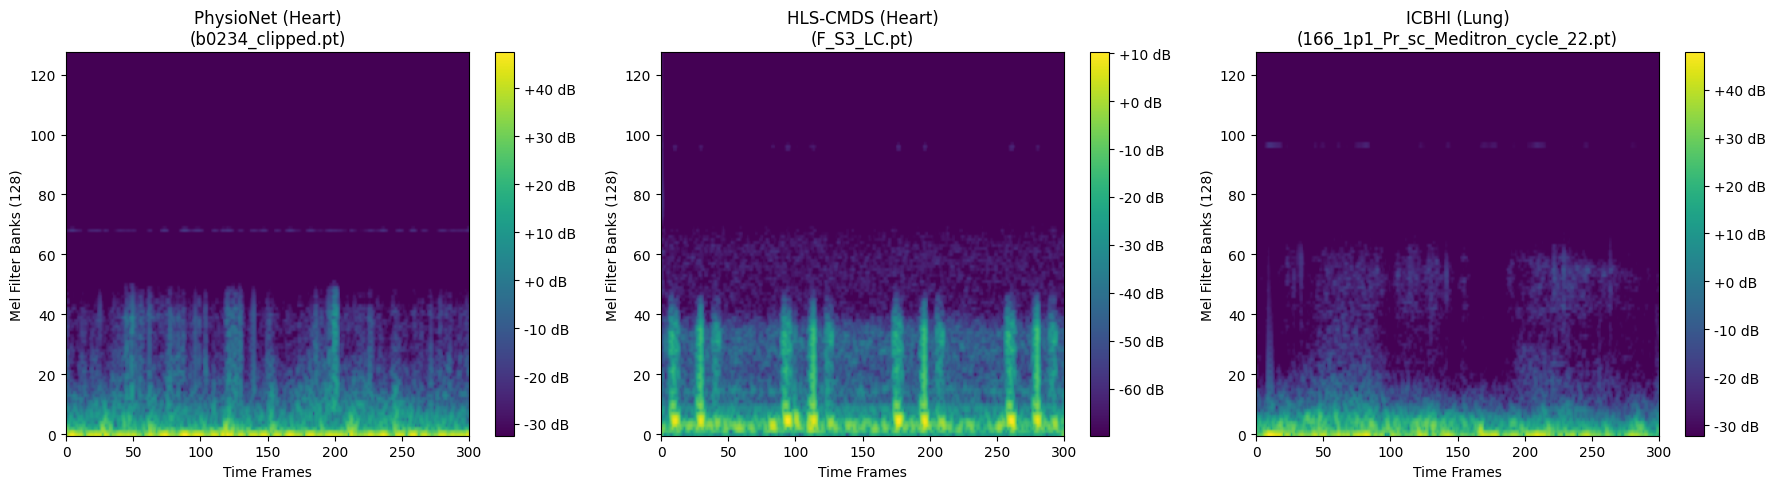

In [21]:
import os
import torch
import matplotlib.pyplot as plt

def visualize_sample_spectrograms(dataset_dict):
    """
    Loads and plots one sample log-Mel spectrogram from each dataset dictionary.
    dataset_dict format: {"Dataset Name": "directory_path"}
    """
    fig, axes = plt.subplots(1, len(dataset_dict), figsize=(18, 5))

    for i, (name, directory) in enumerate(dataset_dict.items()):
        ax = axes[i] if len(dataset_dict) > 1 else axes

        if not os.path.exists(directory):
            ax.text(0.5, 0.5, f"Directory not found:\n{directory}", ha='center', va='center')
            ax.set_title(name)
            continue

        # Find the first .pt file in the directory
        files = [f for f in os.listdir(directory) if f.endswith('.pt')]

        if files:
            file_path = os.path.join(directory, files[0])
            # Load the tensor (shape: [1, n_mels, time_frames])
            spec_tensor = torch.load(file_path)

            # Remove the channel/batch dimension to get a 2D array [n_mels, time]
            spec_2d = spec_tensor.squeeze(0).numpy()

            # Plot using matplotlib
            im = ax.imshow(spec_2d, aspect='auto', origin='lower', cmap='viridis')
            ax.set_title(f"{name}\n({files[0]})")
            ax.set_xlabel("Time Frames")
            ax.set_ylabel("Mel Filter Banks (128)")
            fig.colorbar(im, ax=ax, format='%+2.0f dB')
        else:
            ax.text(0.5, 0.5, "No .pt files found", ha='center', va='center')
            ax.set_title(name)

    plt.tight_layout()
    plt.show()

# Map your spectrogram directories here
spectrogram_folders = {
    "PhysioNet (Heart)": "/content/spectrograms_physionet",
    "HLS-CMDS (Heart)": "/content/spectrograms_hlscmds",
    "ICBHI (Lung)": "/content/spectrograms_icbhi"
}

visualize_sample_spectrograms(spectrogram_folders)

In [22]:
import pandas as pd

# Example: Assuming you saved metadata DataFrames for each dataset during conversion
# physio_df, hls_meta_df, icbhi_df should have columns ["path", "label"]

# Optional: Add a source tag if you want to track which dataset a sample came from
# Update your metadata dataframe paths to point to the SPECTROGRAM folders, not processed waveforms
physio_df["path"] = physio_df["path"].str.replace("processed_physionet", "spectrograms_physionet")
hls_meta_df["path"] = hls_meta_df["path"].str.replace("processed_hlscmds", "spectrograms_hlscmds")
icbhi_df["path"] = icbhi_df["path"].str.replace("processed_icbhi", "spectrograms_icbhi")

# Re-combine into your master dataframe
master_df = pd.concat([physio_df, hls_meta_df, icbhi_df], ignore_index=True)

print(f"Total unified dataset size: {len(master_df)} samples")

Total unified dataset size: 10188 samples


In [23]:
import torch
from torch.utils.data import Dataset

class UnifiedMedicalAudioDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        """
        Args:
            dataframe (pd.DataFrame): Master dataframe containing 'path' and 'label' columns.
            transform (callable, optional): Optional transform to be applied on a sample (e.g., normalization).
        """
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Load the precomputed Log-Mel spectrogram tensor (shape: [1, 128, time_frames])
        spectrogram = torch.load(row["path"])

        # Extract the integer label
        label = int(row["label"])

        # Optional transformations (e.g., SpecAugment or instance normalization)
        if self.transform:
            spectrogram = self.transform(spectrogram)

        return spectrogram, label

In [24]:
from torch.utils.data import DataLoader

# 1. Instantiate the dataset
train_dataset = UnifiedMedicalAudioDataset(master_df)

# 2. Create the DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=16,          # Adjust batch size based on your GPU VRAM
    shuffle=True,           # Shuffle for training robustness
    num_workers=2           # Uses CPU workers to load files concurrently
)

# Quick sanity check: fetch one batch
for batch_specs, batch_labels in train_loader:
    print("Batch spectrogram shape:", batch_specs.shape)  # Expected: [batch_size, 1, 128, time_frames]
    print("Batch labels shape:", batch_labels.shape)        # Expected: [batch_size]
    break

Batch spectrogram shape: torch.Size([16, 1, 128, 301])
Batch labels shape: torch.Size([16])


In [25]:
from transformers import ASTForAudioClassification
import torch

# Using the heavily downloaded 0.4593 checkpoint
model_name = "MIT/ast-finetuned-audioset-10-10-0.4593"

model = ASTForAudioClassification.from_pretrained(
    model_name,
    num_labels=4,            # Adjust based on your max number of classes (e.g., ICBHI has 4)
    ignore_mismatched_sizes=True # Replaces the final classification head for your medical classes
)

# Move to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print(f"Successfully loaded model: {model_name}")

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Successfully loaded model: MIT/ast-finetuned-audioset-10-10-0.4593


In [26]:
from google.colab import userdata
from huggingface_hub import login

# Securely fetch the token from Colab Secrets
hf_token = userdata.get('HF_TOKEN')

# Log in to Hugging Face
login(token=hf_token)

In [27]:
import glob
import os
import pandas as pd

# 1. Rebuild PhysioNet labels from .hea files (# normal -> 0, # abnormal -> 1)
physio_hea_dir = "/content/drive/MyDrive/training"
hea_labels = {}

for hea_path in glob.glob(os.path.join(physio_hea_dir, "**", "*.hea"), recursive=True):
    rec_id = os.path.splitext(os.path.basename(hea_path))[0].lower()
    with open(hea_path, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read().lower()
    if "# normal" in content:
        hea_labels[rec_id] = 0
    elif "# abnormal" in content:
        hea_labels[rec_id] = 1

physio_rebuilt = physio_df[["path"]].copy()

def get_physio_label(pt_path):
    stem = os.path.splitext(os.path.basename(str(pt_path)))[0].lower()
    rec_id = stem.replace("_clipped", "")
    return hea_labels.get(rec_id, None)

physio_rebuilt["label"] = physio_rebuilt["path"].map(get_physio_label)

# Fallback if .hea files aren't in physio_hea_dir: keep existing physio_df['label']
if physio_rebuilt["label"].isna().all():
    print("Warning: No .hea matches found; falling back to existing physio_df['label'].")
    physio_rebuilt["label"] = physio_df["label"].astype(int)
else:
    unmatched = physio_rebuilt["label"].isna().sum()
    if unmatched > 0:
        print(f"Warning: {unmatched} PhysioNet rows had no matching .hea label.")
    physio_rebuilt["label"] = physio_rebuilt["label"].fillna(physio_df["label"]).astype(int)

# 2. ICBHI: 0 -> 0, everything else -> 1
icbhi_rebuilt = icbhi_df[["path", "label"]].copy()
icbhi_rebuilt["label"] = (icbhi_rebuilt["label"].astype(int) != 0).astype(int)

# 3. HLS-CMDS: 'Normal' -> 0, everything else -> 1
known_paths = set(physio_rebuilt["path"]).union(set(icbhi_rebuilt["path"]))
hls_rebuilt = master_df[~master_df["path"].isin(known_paths)][["path", "label"]].copy()
hls_rebuilt["label"] = (
    hls_rebuilt["label"].astype(str).str.strip().str.lower().ne("normal").astype(int)
)

# 4. Assemble clean binary master_df
master_df = pd.concat([physio_rebuilt, icbhi_rebuilt, hls_rebuilt], ignore_index=True)
master_df["label"] = master_df["label"].astype(int)

print("master_df shape:", master_df.shape)
print("Missing values:\n", master_df.isna().sum())
print("Label counts:\n", master_df["label"].value_counts())

master_df shape: (10188, 2)
Missing values:
 path     0
label    0
dtype: int64
Label counts:
 label
0    6226
1    3962
Name: count, dtype: int64


In [28]:
import os

# Build a lookup from Heart Sound ID -> 0 if 'Normal' else 1
hls_id_to_label = {
    str(row["Heart Sound ID"]).strip(): (
        0 if str(row["Heart Sound Type"]).strip().lower() == "normal" else 1
    )
    for _, row in hls_df.iterrows()
}

mask_hls = master_df["path"].astype(str).str.contains("hls", case=False, na=False)

def fix_hls_label(row):
    stem = os.path.splitext(os.path.basename(str(row["path"])))[0]
    return hls_id_to_label.get(stem, row["label"])

master_df.loc[mask_hls, "label"] = master_df.loc[mask_hls].apply(fix_hls_label, axis=1).astype(int)
print(master_df.loc[mask_hls, "label"].value_counts())

label
1    41
0     9
Name: count, dtype: int64


In [29]:
import os
import re
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit


def extract_recording_id(path: str) -> str:
    """Derive a recording-level group ID from .pt spectrogram paths."""
    stem = os.path.splitext(os.path.basename(str(path)))[0]
    # Group ICBHI cycles belonging to the same recording
    stem = re.sub(r"_cycle_\d+$", "", stem)
    # Group PhysioNet clipped segments belonging to the same recording
    stem = re.sub(r"_clipped$", "", stem)
    return stem


df_split = master_df.copy()
df_split["group_id"] = df_split["path"].map(extract_recording_id)

# Target split proportions: 70% train, 15% validation, 15% test (by group)
test_size = 0.15
val_size_of_remainder = 0.15 / (1.0 - test_size)  # ~0.1765 of non-test groups
seed = 42

# 1. Hold out the test set first
gss_test = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
train_val_idx, test_idx = next(gss_test.split(df_split, df_split["label"], groups=df_split["group_id"]))

train_val_df = df_split.iloc[train_val_idx].reset_index(drop=True)
test_df = df_split.iloc[test_idx].reset_index(drop=True)

# 2. Split remaining data into train and validation sets
gss_val = GroupShuffleSplit(n_splits=1, test_size=val_size_of_remainder, random_state=seed)
train_idx, val_idx = next(gss_val.split(train_val_df, train_val_df["label"], groups=train_val_df["group_id"]))

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

# Sanity checks: zero group overlap and class distributions
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

assert len(train_groups & val_groups) == 0, "Leakage between train and val!"
assert len(train_groups & test_groups) == 0, "Leakage between train and test!"
assert len(val_groups & test_groups) == 0, "Leakage between val and test!"

for split_name, split_data in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    counts = split_data["label"].value_counts().to_dict()
    print(
        f"{split_name:5s} | rows: {len(split_data):4d} | "
        f"groups: {split_data['group_id'].nunique():4d} | labels: {counts}"
    )

Train | rows: 6957 | groups: 2946 | labels: {0: 4300, 1: 2657}
Val   | rows: 1656 | groups:  632 | labels: {0: 973, 1: 683}
Test  | rows: 1575 | groups:  632 | labels: {0: 953, 1: 622}


In [30]:
import torch
from torch.utils.data import DataLoader, Dataset


class SpectrogramDataset(Dataset):
    def __init__(self, df, path_col="path", label_col="label", transform=None):
        self.df = df.reset_index(drop=True)
        self.path_col = path_col
        self.label_col = label_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        spec = torch.load(row[self.path_col], map_location="cpu")

        # Handle dict-saved tensors if a .pt file stores {"spectrogram": tensor, ...}
        if isinstance(spec, dict):
            for key in ("spectrogram", "spec", "tensor", "input_values", "data"):
                if key in spec and torch.is_tensor(spec[key]):
                    spec = spec[key]
                    break

        if not torch.is_tensor(spec):
            spec = torch.as_tensor(spec)

        spec = spec.float()

        # Remove singleton leading batch dim if present, e.g. (1, freq, time) -> (freq, time)
        if spec.ndim == 3 and spec.shape[0] == 1:
            spec = spec.squeeze(0)

        if self.transform is not None:
            spec = self.transform(spec)

        # torch.long works with CrossEntropyLoss and ASTForAudioClassification (num_labels=2)
        label = torch.tensor(int(row[self.label_col]), dtype=torch.long)
        return spec, label


def create_dataloaders(
    train_df,
    val_df,
    test_df,
    batch_size=32,
    num_workers=2,
    pin_memory=True,
    train_transform=None,
    eval_transform=None,
):
    train_dataset = SpectrogramDataset(train_df, transform=train_transform)
    val_dataset = SpectrogramDataset(val_df, transform=eval_transform)
    test_dataset = SpectrogramDataset(test_df, transform=eval_transform)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=pin_memory,
        drop_last=False,
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=pin_memory,
        drop_last=False,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=pin_memory,
        drop_last=False,
    )
    return train_loader, val_loader, test_loader


# Example usage & quick batch shape check
train_loader, val_loader, test_loader = create_dataloaders(
    train_df,
    val_df,
    test_df,
    batch_size=32,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

sample_x, sample_y = next(iter(train_loader))
print("Batch spectrogram shape:", sample_x.shape, sample_x.dtype)
print("Batch label shape:", sample_y.shape, sample_y.dtype)
print("Unique labels in first batch:", sample_y.unique().tolist())

Batch spectrogram shape: torch.Size([32, 128, 301]) torch.float32
Batch label shape: torch.Size([32]) torch.int64
Unique labels in first batch: [0, 1]


In [31]:
import torch.nn.functional as F

target_length = model.config.max_length  # 1024 for MIT/ast-finetuned-audioset-10-10-0.4593

def prepare_ast_inputs(specs, target_length=1024):
    # specs arrives as (batch, freq=128, time=301)
    current_time = specs.shape[-1]
    if current_time < target_length:
        # Pad along the last dimension (time): (pad_left_time, pad_right_time)
        specs = F.pad(specs, (0, target_length - current_time), mode="constant", value=0.0)
    elif current_time > target_length:
        specs = specs[..., :target_length]

    # Convert (batch, freq=128, time=1024) -> (batch, time=1024, freq=128)
    return specs.transpose(1, 2)

In [32]:
from collections import Counter
import torch

shape_counts = Counter()
bad_files = []

for path in master_df["path"]:
    try:
        tensor = torch.load(path, map_location="cpu")
        if isinstance(tensor, dict):
            for key in ("spectrogram", "spec", "tensor", "input_values", "data"):
                if key in tensor and torch.is_tensor(tensor[key]):
                    tensor = tensor[key]
                    break
        shape_counts[tuple(tensor.shape)] += 1
    except Exception as exc:
        bad_files.append((path, str(exc)))

print("Unique tensor shapes across dataset:", dict(shape_counts))
print("Files that failed to load:", len(bad_files))

Unique tensor shapes across dataset: {(1, 128, 301): 10188}
Files that failed to load: 0


In [33]:
import torch.nn.functional as F

target_length = model.config.max_length  # 1024 for MIT/ast-finetuned-audioset-10-10-0.4593

def prepare_ast_inputs(specs, target_length=1024):
    # specs arrives as (batch, freq=128, time=301)
    current_time = specs.shape[-1]
    if current_time < target_length:
        # Pad along the last dimension (time): (pad_left_time, pad_right_time)
        specs = F.pad(specs, (0, target_length - current_time), mode="constant", value=0.0)
    elif current_time > target_length:
        specs = specs[..., :target_length]

    # Convert (batch, freq=128, time=1024) -> (batch, time=1024, freq=128)
    return specs.transpose(1, 2)

In [34]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset


class SpectrogramDataset(Dataset):
    def __init__(self, df, path_col="path", label_col="label", transform=None):
        self.df = df.reset_index(drop=True)
        self.path_col = path_col
        self.label_col = label_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        spec = torch.load(row[self.path_col], map_location="cpu")

        if isinstance(spec, dict):
            for key in ("spectrogram", "spec", "tensor", "input_values", "data"):
                if key in spec and torch.is_tensor(spec[key]):
                    spec = spec[key]
                    break

        if not torch.is_tensor(spec):
            spec = torch.as_tensor(spec)

        spec = spec.float()

        if spec.ndim == 3 and spec.shape[0] == 1:
            spec = spec.squeeze(0)

        if self.transform is not None:
            spec = self.transform(spec)

        label = torch.tensor(int(row[self.label_col]), dtype=torch.long)
        return spec, label


def create_dataloaders(
    train_df,
    val_df,
    test_df,
    batch_size=16,
    num_workers=2,
    pin_memory=True,
    train_transform=None,
    eval_transform=None,
):
    train_dataset = SpectrogramDataset(train_df, transform=train_transform)
    val_dataset = SpectrogramDataset(val_df, transform=eval_transform)
    test_dataset = SpectrogramDataset(test_df, transform=eval_transform)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=pin_memory,
        drop_last=False,
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=pin_memory,
        drop_last=False,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=pin_memory,
        drop_last=False,
    )
    return train_loader, val_loader, test_loader


def prepare_ast_inputs(specs: torch.Tensor, target_len: int = 1024) -> torch.Tensor:
    if specs.ndim == 4 and specs.shape[1] == 1:
        specs = specs.squeeze(1)

    current_time = specs.shape[-1]
    if current_time < target_len:
        specs = F.pad(specs, (0, target_len - current_time), mode="constant", value=0.0)
    elif current_time > target_len:
        specs = specs[..., :target_len]

    return specs.transpose(1, 2)


assert all(name in globals() for name in ("train_df", "val_df", "test_df")), (
    "train_df, val_df, or test_df is missing—re-run the split cell first."
)

target_length = 1024
train_loader, val_loader, test_loader = create_dataloaders(
    train_df,
    val_df,
    test_df,
    batch_size=16,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

assert len(train_loader) > 0, "train_loader has 0 batches."

specs, labels = next(iter(train_loader))
prepared_inputs = prepare_ast_inputs(specs, target_len=target_length)

print("Number of batches in train_loader:", len(train_loader))
print("Raw specs shape & dtype:       ", specs.shape, specs.dtype)
print("Prepared input_values shape:   ", prepared_inputs.shape, prepared_inputs.dtype)
print("Labels shape, dtype & unique:  ", labels.shape, labels.dtype, labels.unique(return_counts=True))
print(
    f"Specs stats -> min: {specs.min().item():.4f}, "
    f"max: {specs.max().item():.4f}, mean: {specs.mean().item():.4f}"
)
print("Contains NaN or Inf in specs?  ", bool(torch.isnan(specs).any() or torch.isinf(specs).any()))

Number of batches in train_loader: 435
Raw specs shape & dtype:        torch.Size([16, 128, 301]) torch.float32
Prepared input_values shape:    torch.Size([16, 1024, 128]) torch.float32
Labels shape, dtype & unique:   torch.Size([16]) torch.int64 (tensor([0, 1]), tensor([10,  6]))
Specs stats -> min: -55.7679, max: 49.3969, mean: -28.1258
Contains NaN or Inf in specs?   False


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score
from transformers import ASTForAudioClassification

# 1. Model, device, optimizer, and loss setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
model_name = "MIT/ast-finetuned-audioset-10-10-0.4593"

model = ASTForAudioClassification.from_pretrained(
    model_name,
    num_labels=2,
    ignore_mismatched_sizes=True,
).to(device)

target_length = model.config.max_length  # 1024 for this checkpoint
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-2)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def prepare_ast_inputs(specs: torch.Tensor, target_len: int = 1024) -> torch.Tensor:
    """Pad/trim time axis to target_len and transpose (B, F, T) -> (B, T, F)."""
    if specs.ndim == 4 and specs.shape[1] == 1:
        specs = specs.squeeze(1)

    current_time = specs.shape[-1]
    if current_time < target_len:
        specs = F.pad(specs, (0, target_len - current_time), mode="constant", value=0.0)
    elif current_time > target_len:
        specs = specs[..., :target_len]

    # (batch_size, num_mel_bins=128, max_length=1024) -> (batch_size, 1024, 128)
    return specs.transpose(1, 2)


def run_epoch(loader, is_train: bool = True):
    model.train() if is_train else model.eval()
    total_loss = 0.0
    all_preds = []
    all_targets = []

    grad_ctx = torch.enable_grad() if is_train else torch.no_grad()
    with grad_ctx:
        for specs, labels in loader:
            input_values = prepare_ast_inputs(specs, target_len=target_length).to(
                device, non_blocking=True
            )
            labels = labels.to(device, non_blocking=True)

            if is_train:
                optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(device_type=device.type, enabled=use_amp):
                outputs = model(input_values=input_values)
                logits = outputs.logits
                loss = criterion(logits, labels)

            if is_train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * labels.size(0)
            preds = torch.argmax(logits, dim=-1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    f1 = f1_score(all_targets, all_preds, pos_label=1, zero_division=0)
    return avg_loss, acc, f1


# 2. Training & validation loop
num_epochs = 10
best_val_f1 = -1.0
best_weights_path = "best_ast_model.pt"

for epoch in range(1, num_epochs + 1):
    train_loss, train_acc, train_f1 = run_epoch(train_loader, is_train=True)
    val_loss, val_acc, val_f1 = run_epoch(val_loader, is_train=False)

    print(
        f"Epoch {epoch:02d}/{num_epochs:02d} | "
        f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), best_weights_path)
        print(f"  -> Saved new best checkpoint to '{best_weights_path}' (Val F1: {best_val_f1:.4f})")

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([2])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [ ]:
import glob
import os
import pandas as pd

# 1. Check if physio_df exists in current memory
if "physio_df" in globals() and isinstance(physio_df, pd.DataFrame):
    print("=== physio_df FOUND in memory ===")
    print("Shape:", physio_df.shape)
    print("Columns:", physio_df.columns.tolist())
    print("Dtypes:\n", physio_df.dtypes)
    print("Nulls:\n", physio_df.isna().sum())
    if "label" in physio_df.columns:
        print("Label counts:\n", physio_df["label"].value_counts(dropna=False))
    print("\nFirst 5 rows:")
    print(physio_df.head(5))
else:
    print("=== physio_df NOT found in current memory ===")

# 2. Inspect PhysioNet entries inside master_df (if master_df exists)
if "master_df" in globals() and isinstance(master_df, pd.DataFrame):
    physio_in_master = master_df[
        master_df["path"].astype(str).str.contains("physionet", case=False, na=False)
    ].copy()
    print("\n=== PhysioNet rows inside master_df ===")
    print("Count:", len(physio_in_master))
    if len(physio_in_master) > 0 and "label" in physio_in_master.columns:
        print("Label counts:\n", physio_in_master["label"].value_counts(dropna=False))
    print(physio_in_master.head(5))
else:
    print("\n=== master_df NOT found in current memory either ===")

# 3. Check PhysioNet files on disk (update path if your folders are elsewhere)
pt_matches = glob.glob("/content/**/*physionet*/*.pt", recursive=True) + glob.glob(
    "/content/**/spectrograms_physionet/*.pt", recursive=True
)
hea_matches = glob.glob("/content/**/*.hea", recursive=True)
print(f"\nFound {len(set(pt_matches))} PhysioNet .pt files and {len(set(hea_matches))} .hea files under /content.")